<a id="ktvd-top"></a>

# Lab01 — блок КТвД

**Доп. задание КТвД к лабораторной работе №1 «Случайные величины».**
Основная часть (ИнфоХимия, датасет ESOL) — растворимость органических молекул. В этом блоке — отдельный датасет и две величины по нему, плюс интерактивный генератор на marimo.

> Код во всех ячейках скрыт. В Jupyter раскрывается кликом по «…» слева от ячейки, в Colab — двойным кликом по заголовку формы.

<a id="ktvd-toc"></a>

### Оглавление

| № | Раздел | Что внутри |
|---|---|---|
| К.0 | [Задачи КТвД](#ktvd-0) | чек-лист критериев и доп. заданий, обозначения |
| К.1 | [Датасет Wine Quality](#ktvd-1) | источник, единицы измерения, качество данных |
| К.2 | [Random Variable K1 — pH](#ktvd-2) | природа события, доказательство случайности, EDA и распределение |
| К.3 | [Random Variable K2 — фиксированная кислотность](#ktvd-3) | то же для второй величины |
| К.4 | [Зависимость pH и кислотности](#ktvd-4) | проверка $H_0$ о независимости, химическая интерпретация |
| К.5 | [Интерактивный генератор (marimo)](#ktvd-5) | как запустить, что умеет |
| К.6 | [Lab resume КТвД](#ktvd-6) | выводы и `cat_mark_table` |

<a id="ktvd-0"></a>

## К.0 Задачи КТвД

<a id="ktvd-0-1"></a>

### К.0.1 Чек-лист

**Критерии оформления** (относятся ко всему документу)

| # | Критерий | Как сделано в блоке КТвД | Статус |
|---|---|---|---|
| 1 | Индексы разделов | сквозная нумерация К.0 … К.6, подразделы К.2.1 … | ✅ |
| 2 | Якорные ссылки | [оглавление](#ktvd-toc) + ссылки «↑ к оглавлению» в конце разделов, рабочие ссылки в `cat_mark_table` | ✅ |
| 3 | Скрытие кода | у каждой code-ячейки `source_hidden` (Jupyter) и `cellView: form` (Colab) | ✅ |
| 4 | Масштабы и единицы на графиках | у каждой оси подпись и единица; pH отмечен как безразмерный; логарифмическая ось там, где величина мультипликативная | ✅ |
| 5 | Единая стилистика графиков | одна палитра (проверена на различимость при дальтонизме), один шрифт, одинаковые поля и сетка — задаётся одной функцией в ячейке настройки | ✅ |
| 6 | Формулы в LaTeX, единообразно | все формулы в LaTeX, обозначения сведены в таблицу ниже | ✅ |

**Доп. задание КТвД**

| # | Задача | Где | Статус |
|---|---|---|---|
| 7 | Отдельный датасет и две случайные величины | [К.1](#ktvd-1): Wine Quality, pH и фиксированная кислотность | ✅ |
| 8 | Доказать, что это случайные величины | [К.2.2](#ktvd-2-2), [К.3.2](#ktvd-3-2) | ✅ |
| 9 | Величины одной природы → доказать зависимость | [К.4](#ktvd-4) | ✅ |
| 10 | EDA | [К.2.3](#ktvd-2-3), [К.3.3](#ktvd-3-3) | ✅ |
| 11 | Интерактивность для генератора | [К.5](#ktvd-5) | ✅ |
| 12 | Использование marimo | [К.5](#ktvd-5), файл `ktvd_generator_marimo.py` | ✅ |

**Осталось применить к основной части (ИнфоХимия)**

| # | Что поправить | Где |
|---|---|---|
| 13 | `LogS` — десятичный логарифм, он безразмерный. Подписи «LogS (моль/л)» на осях и «$\mu \approx -3.05$ моль/л» в тексте заменить на «$\lg S$, $S$ в моль/л» | RV 01, sprint 2 |
| 14 | Перевести графики на ту же палитру и стиль (сейчас royalblue, skyblue, teal, purple, darkorange, crimson и стандартные синий/красный в Q-Q) | все графики |
| 15 | В `cat_mark_table` ссылки стоят в обратных кавычках и не совпадают с id заголовков — заменить на `[текст](#id)` с явными `<a id>` | оба cat_mark_table |
| 16 | Скрыть код и пронумеровать разделы так же, как здесь | весь ноутбук |
| 17 | Привести обозначения к одной системе: в тексте встречаются и $\text{Skewness}$, и «асимметрия» — лучше $\gamma_1$, $\gamma_2$ | описания распределений |

<a id="ktvd-0-2"></a>

### К.0.2 Обозначения

| Символ | Смысл | Символ | Смысл |
|---|---|---|---|
| $X$ | случайная величина | $x_1,\dots,x_n$ | наблюдения, $n$ — объём выборки |
| $\bar{x}$ | выборочное среднее | $s$, $s^2$ | выборочное СКО и дисперсия (с поправкой $n-1$) |
| $Q_1,\ Q_3$ | нижний и верхний квартили | $\mathrm{IQR} = Q_3 - Q_1$ | межквартильный размах |
| $\gamma_1$ | коэффициент асимметрии | $\gamma_2$ | эксцесс (у нормального $\gamma_2 = 0$) |
| $r$ | корреляция Пирсона | $\rho_S$, $\tau$ | ранговые корреляции Спирмена и Кендалла |
| $H_0$, $H_1$ | нулевая и альтернативная гипотезы | $\alpha = 0.05$ | уровень значимости во всех тестах |
| $R^2$ | доля дисперсии, объяснённая моделью | $\mathrm{AIC} = 2k - 2\ln L$ | критерий Акаике, $k$ — число параметров |

[↑ к оглавлению](#ktvd-toc)

In [1]:
#@title Настройка: библиотеки, единый стиль графиков, вспомогательные функции
import io
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore")
RNG_SEED = 42
ALPHA = 0.05

# ── Единая палитра (dataviz reference palette, первые три слота проверены на CVD) ──
STYLE = {
    "surface": "#fcfcfb",
    "ink": "#0b0b0b",          # основной текст, теоретические кривые
    "ink2": "#52514e",         # подписи осей, вторичный текст
    "grid": "#e6e5e0",         # сетка — сплошная, едва заметная
    "neutral": "#c3c2b7",      # «прочие» данные
    "pH": "#2a78d6",           # K1 — pH (синий, слот 1)
    "FA": "#eb6834",           # K2 — фиксированная кислотность (оранжевый, слот 2)
    "seq": ["#fcfcfb", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"],
}

mpl.rcParams.update({
    "figure.facecolor": STYLE["surface"], "axes.facecolor": STYLE["surface"],
    "savefig.facecolor": STYLE["surface"], "figure.dpi": 110,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.labelsize": 10, "axes.labelcolor": STYLE["ink2"], "axes.edgecolor": STYLE["grid"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": STYLE["grid"], "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.axisbelow": True,
    "xtick.color": STYLE["ink2"], "ytick.color": STYLE["ink2"],
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2,
})

UNITS = {"pH": "pH, безразмерная", "fixed acidity": "г/дм³"}
LABEL = {"pH": "pH", "fixed acidity": "Фикс. кислотность"}
COLOR = {"pH": STYLE["pH"], "fixed acidity": STYLE["FA"]}
STEP = {"pH": 0.01, "fixed acidity": 0.1}   # шаг, с которым величина записана в датасете
RU = {"fixed acidity": "Фикс. кисл., г/дм³", "volatile acidity": "Летучая кисл., г/дм³",
      "citric acid": "Лимонная к-та, г/дм³", "pH": "pH"}


def axis_label(col):
    return f"{LABEL[col]}, {UNITS[col]}" if col != "pH" else "pH (безразмерная)"


def step_bins(x, step):
    """Бины, кратные шагу записи прибора: иначе дискретные значения дают «зубчатую» гистограмму."""
    width = np.diff(np.histogram_bin_edges(x, bins="fd"))[0]
    width = step * max(1, round(width / step))
    return np.arange(x.min() - step / 2, x.max() + width, width)


def show(df, caption=None, fmt="{:.4g}", highlight_row=None):
    """Аккуратный вывод таблицы: без индекса, с подписью, при желании — подсветка строки."""
    try:
        sty = df.style.hide(axis="index").format(fmt, subset=df.select_dtypes("number").columns)
        if caption:
            sty = sty.set_caption(caption)
        sty = sty.set_table_styles([
            {"selector": "caption", "props": "caption-side: top; text-align: left; font-weight: 600; color: #0b0b0b; padding-bottom: 6px;"},
            {"selector": "th", "props": "text-align: left; color: #52514e; font-weight: 600; border-bottom: 1px solid #c3c2b7;"},
            {"selector": "td", "props": "text-align: left; padding: 3px 10px;"},
        ])
        if highlight_row is not None:
            sty = sty.apply(lambda r: ["background-color: #cde2fb" if r.name == highlight_row else "" for _ in r], axis=1)
        display(sty)
    except Exception:
        if caption:
            print(caption)
        display(df)


def describe_rv(x, col):
    """Сводная таблица описательных статистик (тот же набор, что в основной части + CV)."""
    s = pd.Series(x)
    q1, q3 = s.quantile([0.25, 0.75])
    rows = [
        ("Объём выборки n", s.count(), "шт."),
        ("Среднее x̄", s.mean(), UNITS[col]),
        ("Медиана", s.median(), UNITS[col]),
        ("Мода", s.mode().iloc[0], UNITS[col]),
        ("Дисперсия s²", s.var(), f"({UNITS[col]})²" if col != "pH" else "—"),
        ("СКО s", s.std(), UNITS[col]),
        ("Коэф. вариации s / x̄", s.std() / s.mean(), "—"),
        ("Минимум", s.min(), UNITS[col]),
        ("Квартиль Q₁", q1, UNITS[col]),
        ("Квартиль Q₃", q3, UNITS[col]),
        ("Максимум", s.max(), UNITS[col]),
        ("IQR = Q₃ − Q₁", q3 - q1, UNITS[col]),
        ("Выбросы по правилу 1.5·IQR", int(((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).sum()), "шт."),
        ("Асимметрия γ₁", s.skew(), "—"),
        ("Эксцесс γ₂", s.kurtosis(), "—"),
    ]
    return pd.DataFrame(rows, columns=["Статистика", "Значение", "Ед. изм."])


def runs_test(x):
    """Критерий серий Вальда–Вольфовица относительно медианы (проверка независимости порядка)."""
    x = np.asarray(x)
    m = np.median(x)
    s = (x > m)[x != m]
    n1, n2 = s.sum(), (~s).sum()
    r = 1 + np.sum(s[1:] != s[:-1])
    mu = 2 * n1 * n2 / (n1 + n2) + 1
    var = 2 * n1 * n2 * (2 * n1 * n2 - n1 - n2) / ((n1 + n2) ** 2 * (n1 + n2 - 1))
    z = (r - mu) / np.sqrt(var)
    return r, mu, z, 2 * stats.norm.sf(abs(z))


def cv_regression(X, y, quadratic=False, k=5, seed=RNG_SEED):
    """k-fold кросс-валидация МНК-регрессии на numpy. Возвращает R², RMSE и предсказания."""
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(y))
    pred = np.empty_like(y, dtype=float)

    def design(Z):
        cols = [np.ones(len(Z)), *Z.T]
        if quadratic:
            p = Z.shape[1]
            cols += [Z[:, i] * Z[:, j] for i in range(p) for j in range(i, p)]
        return np.column_stack(cols)

    for fold in np.array_split(idx, k):
        train = np.setdiff1d(idx, fold)
        mu, sd = X[train].mean(0), X[train].std(0)
        A = design((X[train] - mu) / sd)
        beta = np.linalg.lstsq(A, y[train], rcond=None)[0]
        pred[fold] = design((X[fold] - mu) / sd) @ beta
    resid = y - pred
    r2 = 1 - np.sum(resid ** 2) / np.sum((y - y.mean()) ** 2)
    return r2, np.sqrt(np.mean(resid ** 2)), pred


CANDIDATES = {"Нормальное": stats.norm, "Логистическое": stats.logistic,
              "Логнормальное": stats.lognorm, "Гамма": stats.gamma}


def fit_candidates(x):
    rows = []
    for name, dist in CANDIDATES.items():
        params = dist.fit(x)
        loglik = dist.logpdf(x, *params).sum()
        ks = stats.kstest(x, dist(*params).cdf)
        rows.append({"Распределение": name, "Параметров k": len(params),
                     "AIC": 2 * len(params) - 2 * loglik, "KS: D": ks.statistic, "KS: p-value": ks.pvalue,
                     "Вывод (α = 0.05)": "не отвергается" if ks.pvalue > ALPHA else "отвергается",
                     "_params": params, "_dist": dist})
    return pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)


def eda_figure(x, col, fits):
    """Три панели в одном формате: гистограмма + 2 лучшие модели, ящик с усами, Q-Q к нормальному."""
    c = COLOR[col]
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.9), gridspec_kw={"width_ratios": [1.35, 1, 1]})

    # 1 — гистограмма плотности и две лучшие по AIC модели
    ax[0].hist(x, bins=step_bins(x, STEP[col]), density=True, color=c, alpha=0.55, edgecolor=STYLE["surface"], linewidth=1)
    grid = np.linspace(x.min() - 0.05 * np.ptp(x), x.max() + 0.05 * np.ptp(x), 400)
    for i, row in fits.head(2).iterrows():
        ax[0].plot(grid, row["_dist"].pdf(grid, *row["_params"]), color=STYLE["ink"] if i == 0 else STYLE["ink2"],
                   linestyle="-" if i == 0 else "--", linewidth=2 if i == 0 else 1.5,
                   label=f"{row['Распределение']} (AIC {row['AIC']:.0f})")
    ax[0].set_title("Плотность: данные и модели")
    ax[0].set_xlabel(axis_label(col)); ax[0].set_ylabel("Плотность вероятности")
    ax[0].legend(loc="upper right")

    # 2 — ящик с усами
    ax[1].boxplot(x, vert=False, widths=0.45, patch_artist=True,
                  boxprops=dict(facecolor=c, alpha=0.35, edgecolor=STYLE["ink2"]),
                  medianprops=dict(color=STYLE["ink"], linewidth=2),
                  whiskerprops=dict(color=STYLE["ink2"]), capprops=dict(color=STYLE["ink2"]),
                  flierprops=dict(marker="o", markersize=4, markerfacecolor=c, markeredgecolor=STYLE["surface"], alpha=0.8))
    ax[1].set_yticks([]); ax[1].grid(axis="y", visible=False)
    ax[1].set_title("Ящик с усами (усы = 1.5·IQR)")
    ax[1].set_xlabel(axis_label(col))

    # 3 — Q-Q к нормальному закону
    (osm, osr), (slope, intercept, _) = stats.probplot(x, dist="norm")
    ax[2].scatter(osm, osr, s=10, color=c, alpha=0.7, edgecolor="none")
    ax[2].plot(osm, slope * osm + intercept, color=STYLE["ink"], linewidth=1.5, label="нормальный закон")
    ax[2].set_title("Q-Q: данные против $\\mathcal{N}(\\bar{x}, s^2)$")
    ax[2].set_xlabel("Теоретические квантили $\\mathcal{N}(0, 1)$")
    ax[2].set_ylabel(axis_label(col))
    ax[2].legend(loc="upper left")
    fig.tight_layout()
    plt.show()


def randomness_figure(y, pred, col, resolution):
    c = COLOR[col]
    resid = y - pred
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.9))
    lo, hi = min(y.min(), pred.min()), max(y.max(), pred.max())
    lim = [lo - 0.03 * (hi - lo), hi + 0.03 * (hi - lo)]
    ax[0].scatter(pred, y, s=10, color=c, alpha=0.5, edgecolor="none")
    ax[0].plot(lim, lim, color=STYLE["ink"], linewidth=1.5, label="идеальная формула $y = \\hat{y}$")
    ax[0].set_xlim(lim); ax[0].set_ylim(lim); ax[0].set_aspect("equal", adjustable="box")
    ax[0].set_title("Измерено против предсказанного по составу")
    ax[0].set_xlabel(f"Предсказано $\\hat{{y}}$ — {axis_label(col)}"); ax[0].set_ylabel(f"Измерено $y$ — {axis_label(col)}")
    ax[0].legend(loc="upper left")

    bins = np.histogram_bin_edges(resid, bins="fd")
    ax[1].hist(resid, bins=bins, color=c, alpha=0.55, edgecolor=STYLE["surface"], linewidth=1)
    ax[1].axvspan(-resolution / 2, resolution / 2, color=STYLE["ink"], alpha=0.12, label=f"шаг записи прибора ±{resolution / 2:g}")
    ax[1].set_title("Остатки: то, что формула не объясняет")
    ax[1].set_xlabel(f"Остаток $y - \\hat{{y}}$ — {axis_label(col)}"); ax[1].set_ylabel("Число вин")
    ax[1].legend(loc="upper right")
    fig.tight_layout()
    plt.show()


print("Стиль и функции загружены.")

Стиль и функции загружены.


<a id="ktvd-1"></a>

## К.1 Датасет: Wine Quality (red)

<a id="ktvd-1-1"></a>

### К.1.1 Источник и единицы

Физико-химические анализы красных вин «винью верде» (Португалия), собранные сертификационной лабораторией CVRVV в 2004–2007 гг. Датасет опубликован в работе Cortez et al. (2009) [1] и лежит в репозитории UCI. Одна строка — одно вино, 11 лабораторных показателей и оценка дегустаторов.

Почему именно он: тема близка к основной части (это тоже химия растворов), а среди показателей есть две величины одной природы — обе описывают **кислотность** вина. Поэтому их можно и нужно проверить на зависимость.

| Величина | Столбец | Что измеряют | Единица |
|---|---|---|---|
| **K1** | `pH` | $\mathrm{pH} = -\lg a_{\mathrm{H_3O^+}}$, «активная» кислотность | безразмерная |
| **K2** | `fixed acidity` | нелетучие кислоты (винная, яблочная, лимонная…) в пересчёте на винную, титрованием | г/дм³ |

<a id="ktvd-1-2"></a>

### К.1.2 Качество данных

In [2]:
#@title Загрузка датасета и проверка качества данных
SOURCES = [
    "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv",
    "https://raw.githubusercontent.com/zygmuntz/wine-quality/master/winequality/winequality-red.csv",
    "winequality-red.csv",  # локальная копия рядом с ноутбуком
]


def load_wine():
    for src in SOURCES:
        try:
            return pd.read_csv(src, sep=";"), src
        except Exception:
            try:  # на macOS с Python 3.14 бывает ошибка сертификатов — как в основной части
                import requests, urllib3
                urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)
                r = requests.get(src, verify=False, timeout=20)
                r.raise_for_status()
                return pd.read_csv(io.StringIO(r.text), sep=";"), src
            except Exception:
                continue
    raise RuntimeError("Датасет не загрузился: положите winequality-red.csv рядом с ноутбуком")


wine_raw, wine_src = load_wine()
n_raw, n_dup = len(wine_raw), int(wine_raw.duplicated().sum())
wine = wine_raw.drop_duplicates().reset_index(drop=True)

quality = pd.DataFrame([
    ("Строк в файле", n_raw),
    ("Полных дубликатов (все 12 столбцов совпадают)", n_dup),
    ("Пропусков", int(wine_raw.isna().sum().sum())),
    ("Строк после удаления дубликатов", len(wine)),
], columns=["Проверка", "Значение"])
show(quality, "Таблица К.1 — качество данных", fmt="{:.0f}")

rows = []
for col in ["pH", "fixed acidity"]:
    r_file, mu_file, z_file, p_file = runs_test(wine[col].values)
    shuffled = wine[col].sample(frac=1, random_state=RNG_SEED).values
    r_sh, mu_sh, z_sh, p_sh = runs_test(shuffled)
    rows += [(LABEL[col], "порядок файла", r_file, mu_file, z_file, p_file),
             (LABEL[col], "после перемешивания", r_sh, mu_sh, z_sh, p_sh)]
runs_df = pd.DataFrame(rows, columns=["Величина", "Порядок строк", "Серий R", "Ожидаемо E[R]", "z", "p-value"])
show(runs_df, "Таблица К.2 — критерий серий: независим ли порядок строк", fmt="{:.4g}")
print(f"Источник: {wine_src}")

Проверка,Значение
Строк в файле,1599
Полных дубликатов (все 12 столбцов совпадают),240
Пропусков,0
Строк после удаления дубликатов,1359


Величина,Порядок строк,Серий R,Ожидаемо E[R],z,p-value
pH,порядок файла,581,661.9,-4.453,8.486e-06
pH,после перемешивания,662,661.9,0.005329,0.9957
Фикс. кислотность,порядок файла,501,661.5,-8.833,1.016e-18
Фикс. кислотность,после перемешивания,648,661.5,-0.7407,0.4589


Источник: https://raw.githubusercontent.com/zygmuntz/wine-quality/master/winequality/winequality-red.csv


**Что видно.** В файле 240 полных дубликатов — 15 % строк. Одинаковые по всем 11 анализам вина почти наверняка повторно внесённые записи, поэтому дальше работаем с $n = 1359$ уникальными винами.

Критерий серий Вальда–Вольфовица [4] по порядку файла отвергает независимость ($p < 0.001$): соседние строки похожи, видимо, вина одной партии или производителя записаны подряд. После случайного перемешивания эффект пропадает ($p > 0.05$). Для распределений и корреляций порядок строк не важен, но подвыборки из этого файла нужно брать только после перемешивания.

[↑ к оглавлению](#ktvd-toc)

<a id="ktvd-2"></a>

## К.2 Random Variable K1 — pH

<a id="ktvd-2-1"></a>

### К.2.1 Description (природа события)

**Событие:** из всех красных вин региона случайно берут одно и измеряют pH на pH-метре. Значение записывается с шагом $0.01$.

**Почему pH — случайная величина, а не функция состава.** pH определяется не только количеством кислот, но и тем, какая их часть нейтрализована катионами, прежде всего калием из винограда. Калий в датасете не измеряли. Дальше на pH влияют сорт и зрелость винограда, погода года, яблочно-молочное брожение и погрешность самого прибора. Из 11 измеренных показателей pH однозначно не получить. Это можно проверить двумя способами:

1. построить «лучшую формулу» pH по остальным 10 показателям и посмотреть, сколько разброса она не объясняет;
2. найти вина-«двойники» с одинаковым набором кислот и сравнить их pH.

<a id="ktvd-2-2"></a>

### К.2.2 Доказательство случайности

Модель (5-fold CV),R²,"Не объяснено, 1 − R²","RMSE (pH, безразмерная)",RMSE / шаг прибора
"Линейная МНК, 10 признаков",0.695,0.305,0.086,8.552
"Квадратичная МНК, 65 членов",0.727,0.273,0.081,8.099


Групп «двойников» (совпадают Фикс. кисл., Летучая кисл., Лимонная к-та): 25, из них с разным значением «pH»: 16


"Фикс. кисл., г/дм³","Летучая кисл., г/дм³","Лимонная к-та, г/дм³",Вин в группе,pH: min,pH: max,Разброс
8.1,0.87,0,2,3.25,3.6,0.35
7,0.685,0,2,3.34,3.6,0.26
5.6,0.66,0,2,3.52,3.71,0.19
7.8,0.56,0.19,3,3.19,3.33,0.14
7.1,0.59,0.01,2,3.42,3.55,0.13


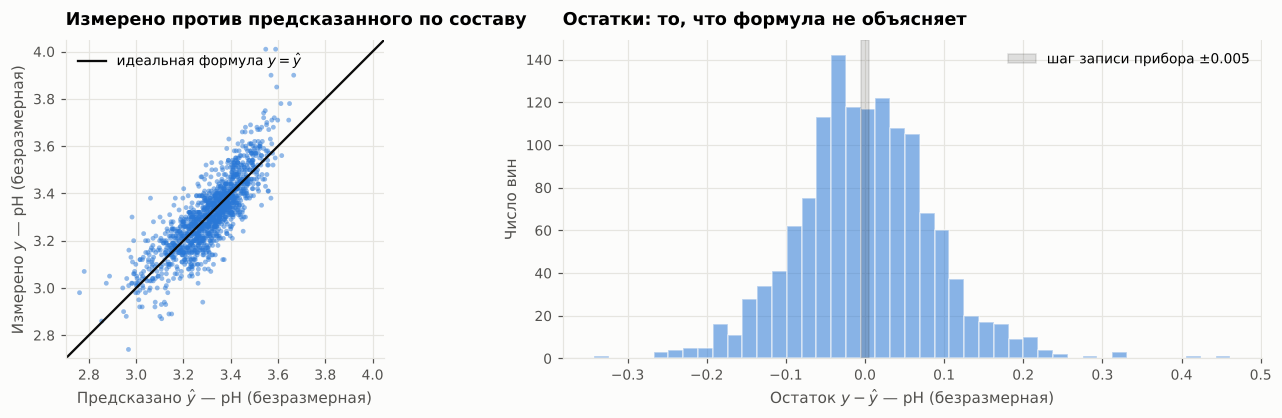

In [3]:
#@title Попытка вычислить pH формулой по остальным 10 показателям
FEATURES = [c for c in wine.columns if c != "quality"]


def randomness_report(target, twin_keys, resolution, table_no):
    X = wine[[c for c in FEATURES if c != target]].values
    y = wine[target].values
    rows, preds = [], {}
    for name, quad in [("Линейная МНК, 10 признаков", False), ("Квадратичная МНК, 65 членов", True)]:
        r2, rmse, pred = cv_regression(X, y, quadratic=quad)
        preds[name] = pred
        rows.append((name, r2, 1 - r2, rmse, rmse / resolution))
    model_df = pd.DataFrame(rows, columns=["Модель (5-fold CV)", "R²", "Не объяснено, 1 − R²",
                                           f"RMSE ({UNITS[target]})", "RMSE / шаг прибора"])
    show(model_df, f"Таблица К.{table_no} — можно ли вычислить «{LABEL[target]}» по остальным 10 показателям", fmt="{:.3f}")

    g = wine.groupby(twin_keys)[target].agg(["count", "min", "max"])
    g = g[g["count"] >= 2]
    g["Разброс"] = g["max"] - g["min"]
    twins = g.sort_values("Разброс", ascending=False).reset_index()
    twins.columns = [*[RU[k] for k in twin_keys], "Вин в группе", f"{LABEL[target]}: min", f"{LABEL[target]}: max", "Разброс"]
    print(f"Групп «двойников» (совпадают {', '.join(RU[k].split(',')[0] for k in twin_keys)}): {len(g)}, "
          f"из них с разным значением «{LABEL[target]}»: {(g['Разброс'] > 0).sum()}")
    show(twins.head(5), f"Таблица К.{table_no + 1} — пять групп «двойников» с наибольшим разбросом «{LABEL[target]}»", fmt="{:.3g}")
    return y, preds["Линейная МНК, 10 признаков"]


y_ph, pred_ph = randomness_report("pH", ["fixed acidity", "volatile acidity", "citric acid"], resolution=0.01, table_no=3)
randomness_figure(y_ph, pred_ph, "pH", resolution=0.01)

**Вывод.** Линейная формула по 10 показателям объясняет $R^2 \approx 0.70$ разброса pH, квадратичная — $0.73$: в шесть раз больше членов почти ничего не добавили. Ошибка предсказания $\approx 0.086$ ед. pH, это в 8–9 раз больше шага записи прибора, то есть дело не в округлении. У «двойников» с одинаковыми фиксированной, летучей и лимонной кислотностью pH отличается до $0.35$. Около 30 % разброса pH остаётся непредсказуемым по измеренному составу, значит pH ведёт себя как случайная величина.

<a id="ktvd-2-3"></a>

### К.2.3 EDA & Distribution

Статистика,Значение,Ед. изм.
Объём выборки n,1359,шт.
Среднее x̄,3.31,"pH, безразмерная"
Медиана,3.31,"pH, безразмерная"
Мода,3.3,"pH, безразмерная"
Дисперсия s²,0.02404,—
СКО s,0.155,"pH, безразмерная"
Коэф. вариации s / x̄,0.04684,—
Минимум,2.74,"pH, безразмерная"
Квартиль Q₁,3.21,"pH, безразмерная"
Квартиль Q₃,3.4,"pH, безразмерная"


Распределение,Параметров k,AIC,KS: D,KS: p-value,Вывод (α = 0.05)
Логистическое,2,-1225,0.02546,0.3362,не отвергается
Логнормальное,3,-1213,0.03341,0.09409,не отвергается
Гамма,3,-1213,0.03378,0.08791,не отвергается
Нормальное,2,-1207,0.03968,0.02693,отвергается


Нормальность pH: Шапиро–Уилк W = 0.9927, p = 3.08e-06;  Д'Агостино K² = 35.08, p = 2.41e-08
Логистическое: μ = 3.3078, s = 0.0865  →  σ = sπ/√3 = 0.1569


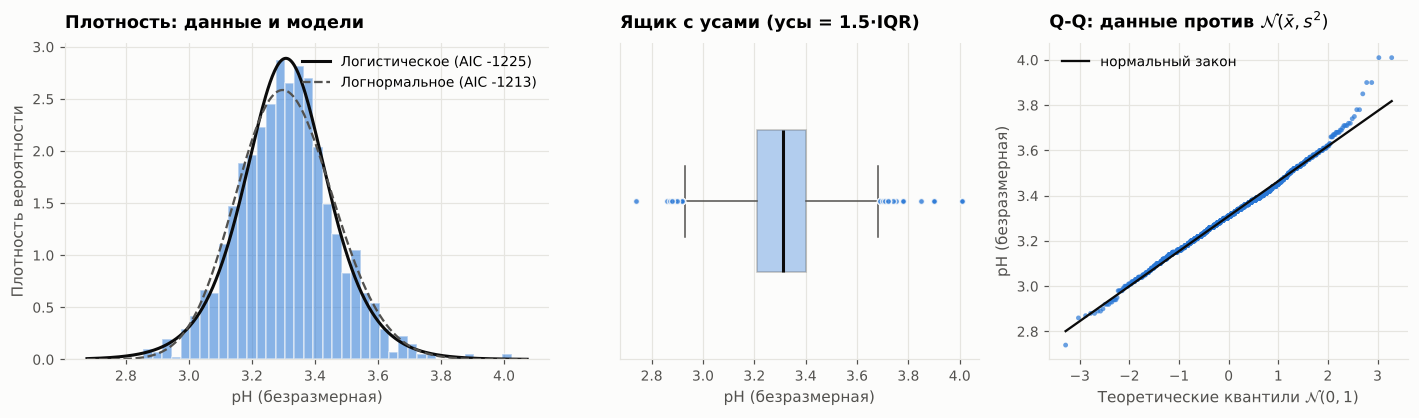

Z-стандартизация: среднее = -0.0000, СКО = 1.0000, γ₁ = 0.2320


In [4]:
#@title Описательные статистики и подбор распределения для pH
x_ph = wine["pH"].values
show(describe_rv(x_ph, "pH"), "Таблица К.5 — описательные статистики pH", fmt="{:.4g}")

fits_ph = fit_candidates(x_ph)
show(fits_ph.drop(columns=["_params", "_dist"]), "Таблица К.6 — какое распределение лучше описывает pH",
     fmt="{:.4g}", highlight_row=0)

sw = stats.shapiro(x_ph); k2 = stats.normaltest(x_ph)
print(f"Нормальность pH: Шапиро–Уилк W = {sw.statistic:.4f}, p = {sw.pvalue:.2e};  "
      f"Д'Агостино K² = {k2.statistic:.2f}, p = {k2.pvalue:.2e}")
loc_ph, s_ph = fits_ph.loc[fits_ph["Распределение"] == "Логистическое", "_params"].iloc[0]
print(f"Логистическое: μ = {loc_ph:.4f}, s = {s_ph:.4f}  →  σ = sπ/√3 = {s_ph * np.pi / np.sqrt(3):.4f}")
eda_figure(x_ph, "pH", fits_ph)

z_ph = (x_ph - x_ph.mean()) / x_ph.std(ddof=1)
print(f"Z-стандартизация: среднее = {z_ph.mean():.4f}, СКО = {z_ph.std(ddof=1):.4f}, γ₁ = {pd.Series(z_ph).skew():.4f}")

**Распределение pH.** Среднее $\bar{x} = 3.31$, медиана тоже $3.31$, асимметрия маленькая ($\gamma_1 = 0.23$), но эксцесс положительный ($\gamma_2 = 0.88$): хвосты тяжелее, чем у нормального закона. Это видно и на Q-Q графике, где крайние точки уходят от прямой. Шапиро–Уилк нормальность отвергает ($p \approx 3 \cdot 10^{-6}$).

Лучшая модель по AIC — **логистическое распределение**, и критерий Колмогорова–Смирнова его не отвергает ($p = 0.34$):

$$
f(x) = \frac{e^{-(x-\mu)/s}}{s\left(1 + e^{-(x-\mu)/s}\right)^2}, \qquad
F(x) = \frac{1}{1 + e^{-(x-\mu)/s}}, \qquad
\sigma^2 = \frac{s^2 \pi^2}{3},
$$

с оценками $\mu = 3.308$, $s = 0.087$. Логистический закон похож на нормальный, но его эксцесс $\gamma_2 = 1.2$ [2], что ближе к нашим $0.88$, чем ноль у нормального. Интересно, что та же модель лучше всего подошла и для $\lg S$ в основной части. Обе величины — логарифмы концентраций, так что совпадение, возможно, не случайное.

*Оговорка: параметры оценены по тем же данным, поэтому p-value критерия КС здесь завышены (поправка Лиллиефорса). Сравнение моделей по AIC от этого не зависит.*

[↑ к оглавлению](#ktvd-toc)

<a id="ktvd-3"></a>

## К.3 Random Variable K2 — фиксированная кислотность

<a id="ktvd-3-1"></a>

### К.3.1 Description (природа события)

**Событие:** у того же случайно выбранного вина титрованием определяют массовую концентрацию нелетучих кислот и пересчитывают на винную кислоту, г/дм³. Шаг записи $0.1$ г/дм³.

**Почему это случайная величина.** Количество винной и яблочной кислоты в ягоде зависит от того, насколько жарким было лето: в тёплый год яблочная кислота «сгорает» при созревании. Потом кислотность меняется при брожении. Яблочно-молочное брожение превращает двухосновную яблочную кислоту в одноосновную молочную и снижает титруемую кислотность. Винодел может ещё и подкислить или раскислить вино. Ничего из этого в таблице нет, так что по остальным показателям кислотность однозначно не вычисляется. Проверка та же, что для pH.

<a id="ktvd-3-2"></a>

### К.3.2 Доказательство случайности

Модель (5-fold CV),R²,"Не объяснено, 1 − R²",RMSE (г/дм³),RMSE / шаг прибора
"Линейная МНК, 10 признаков",0.870,0.130,0.627,6.269
"Квадратичная МНК, 65 членов",0.869,0.131,0.629,6.287


Групп «двойников» (совпадают Летучая кисл., Лимонная к-та, pH): 25, из них с разным значением «Фикс. кислотность»: 16


"Летучая кисл., г/дм³","Лимонная к-та, г/дм³",pH,Вин в группе,Фикс. кислотность: min,Фикс. кислотность: max,Разброс
0.67,0.55,3.17,2,8.1,11.2,3.1
0.33,0.32,3.3,2,6,8.2,2.2
0.69,0,3.35,2,7,9,2
0.43,0.36,3.34,2,7,8,1
0.44,0.49,3.23,2,9,10,1


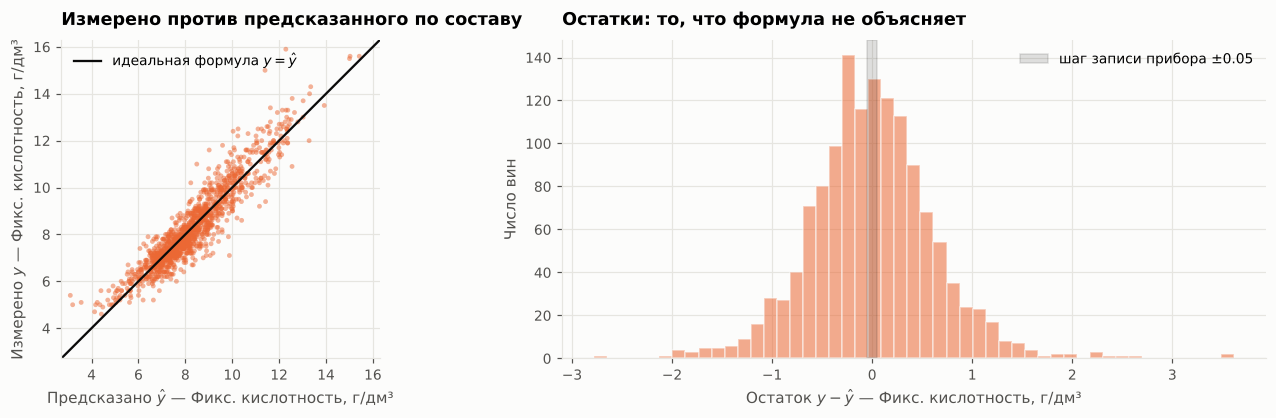

In [5]:
#@title Попытка вычислить фиксированную кислотность формулой по остальным 10 показателям
y_fa, pred_fa = randomness_report("fixed acidity", ["volatile acidity", "citric acid", "pH"], resolution=0.1, table_no=7)
randomness_figure(y_fa, pred_fa, "fixed acidity", resolution=0.1)

**Вывод.** Кислотность предсказывается лучше, чем pH ($R^2 = 0.87$): через плотность и лимонную кислоту она связана с составом сильнее. Но ошибка $\approx 0.63$ г/дм³ в 6 раз больше шага записи, а квадратичная модель не лучше линейной ($R^2 = 0.869$ против $0.870$), то есть мы упёрлись в шум, а не в простоту модели. У вин с одинаковыми летучей кислотностью, лимонной кислотой и pH фиксированная кислотность отличается до $3.1$ г/дм³. Это тоже случайная величина.

<a id="ktvd-3-3"></a>

### К.3.3 EDA & Distribution

Статистика,Значение,Ед. изм.
Объём выборки n,1359,шт.
Среднее x̄,8.311,г/дм³
Медиана,7.9,г/дм³
Мода,7.2,г/дм³
Дисперсия s²,3.017,(г/дм³)²
СКО s,1.737,г/дм³
Коэф. вариации s / x̄,0.209,—
Минимум,4.6,г/дм³
Квартиль Q₁,7.1,г/дм³
Квартиль Q₃,9.2,г/дм³


Распределение,Параметров k,AIC,KS: D,KS: p-value,Вывод (α = 0.05)
Логнормальное,3,5161,0.05183,0.0013,отвергается
Гамма,3,5170,0.05825,0.000189,отвергается
Логистическое,2,5322,0.07474,4.771e-07,отвергается
Нормальное,2,5360,0.1081,2.697e-14,отвергается


Логнормальное (3 параметра): σ = 0.3039, сдвиг x₀ = 2.7535, e^μ = 5.3054


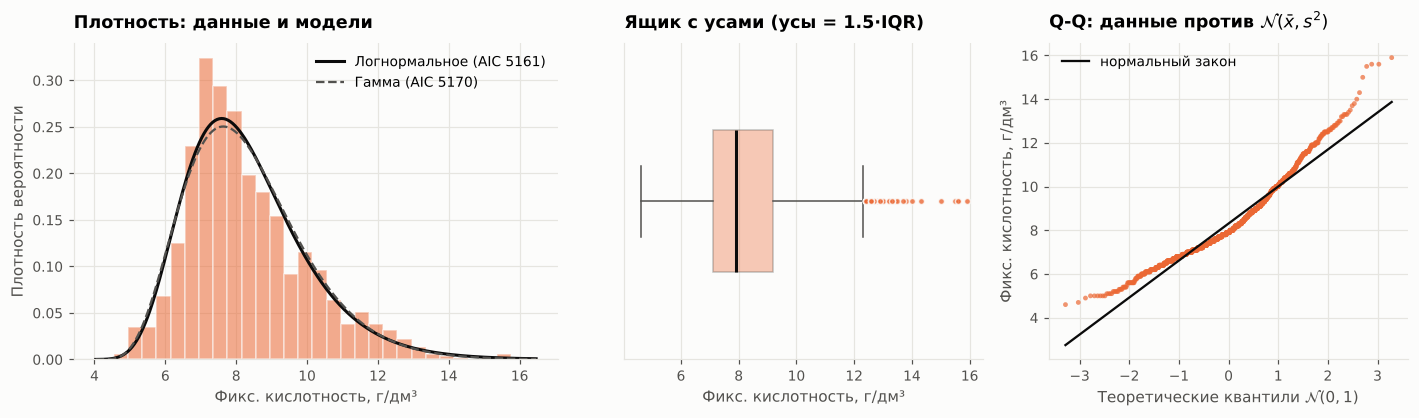

Преобразование,γ₁,γ₂,Шапиро–Уилк p
Z-стандартизация z = (x − x̄) / s,0.941,1.05,9.9e-22
"Логарифм ln x, затем z",0.349,0.0792,1.73e-09
"Бокс–Кокс, λ = -0.59",0.000218,0.0577,2.57e-05


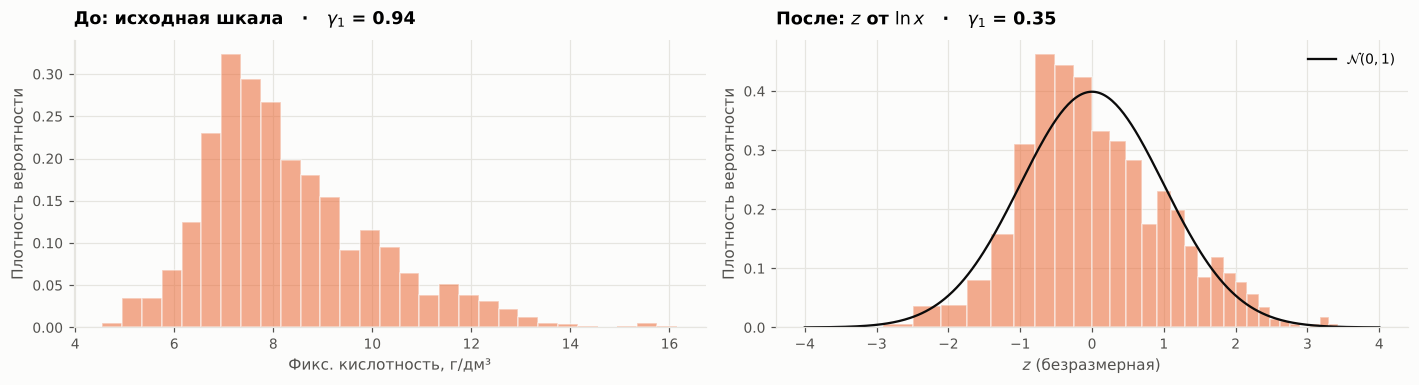

In [6]:
#@title Описательные статистики, подбор распределения и нормализация фиксированной кислотности
x_fa = wine["fixed acidity"].values
show(describe_rv(x_fa, "fixed acidity"), "Таблица К.9 — описательные статистики фиксированной кислотности", fmt="{:.4g}")

fits_fa = fit_candidates(x_fa)
show(fits_fa.drop(columns=["_params", "_dist"]), "Таблица К.10 — какое распределение лучше описывает кислотность",
     fmt="{:.4g}", highlight_row=0)
sigma_ln, loc_ln, scale_ln = fits_fa.loc[fits_fa["Распределение"] == "Логнормальное", "_params"].iloc[0]
print(f"Логнормальное (3 параметра): σ = {sigma_ln:.4f}, сдвиг x₀ = {loc_ln:.4f}, e^μ = {scale_ln:.4f}")
eda_figure(x_fa, "fixed acidity", fits_fa)

# Нормализация: сравниваем три преобразования
ln_fa = np.log(x_fa)
bc_fa, lam = stats.boxcox(x_fa)
norm_df = pd.DataFrame([
    ("Z-стандартизация z = (x − x̄) / s", pd.Series((x_fa - x_fa.mean()) / x_fa.std(ddof=1)).skew(),
     pd.Series((x_fa - x_fa.mean()) / x_fa.std(ddof=1)).kurtosis(), stats.shapiro((x_fa - x_fa.mean()) / x_fa.std(ddof=1)).pvalue),
    ("Логарифм ln x, затем z", pd.Series(ln_fa).skew(), pd.Series(ln_fa).kurtosis(), stats.shapiro(ln_fa).pvalue),
    (f"Бокс–Кокс, λ = {lam:.2f}", pd.Series(bc_fa).skew(), pd.Series(bc_fa).kurtosis(), stats.shapiro(bc_fa).pvalue),
], columns=["Преобразование", "γ₁", "γ₂", "Шапиро–Уилк p"])
show(norm_df, "Таблица К.11 — нормализация кислотности", fmt="{:.3g}")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
edges = step_bins(x_fa, STEP["fixed acidity"])
to_z = lambda v: (np.log(v) - ln_fa.mean()) / ln_fa.std(ddof=1)   # то же преобразование для границ бинов
for a, data_, bins_, title, xl in [
        (ax[0], x_fa, edges, "До: исходная шкала", axis_label("fixed acidity")),
        (ax[1], to_z(x_fa), to_z(edges), "После: $z$ от $\\ln x$", "$z$ (безразмерная)")]:
    a.hist(data_, bins=bins_, density=True, color=STYLE["FA"], alpha=0.55, edgecolor=STYLE["surface"], linewidth=1)
    a.set_title(f"{title}   ·   $\\gamma_1$ = {pd.Series(data_).skew():.2f}")
    a.set_xlabel(xl); a.set_ylabel("Плотность вероятности")
g = np.linspace(-4, 4, 300)
ax[1].plot(g, stats.norm.pdf(g), color=STYLE["ink"], linewidth=1.5, label="$\\mathcal{N}(0, 1)$")
ax[1].legend(loc="upper right")
fig.tight_layout(); plt.show()

**Распределение кислотности.** Типичное значение $7$–$9$ г/дм³ ($Q_1 = 7.1$, $Q_3 = 9.2$), среднее $\bar{x} = 8.31$ больше медианы $7.9$ из-за длинного правого хвоста ($\gamma_1 = 0.94$). Величина строго положительная и складывается из вкладов нескольких кислот, которые зависят от многих условий *мультипликативно*. По ЦПТ для произведений такая величина близка к **логнормальной** (её логарифм нормален — эта связь есть на схеме Leemis & McQueston [2]):

$$
X = x_0 + e^{Y}, \quad Y \sim \mathcal{N}(\mu, \sigma^2) \quad\Longrightarrow\quad
f(x) = \frac{1}{(x - x_0)\,\sigma\sqrt{2\pi}} \exp\!\left(-\frac{\left(\ln(x - x_0) - \mu\right)^2}{2\sigma^2}\right), \quad x > x_0 .
$$

По AIC логнормальная модель лучшая из четырёх, но КС её всё же отвергает ($p = 0.001$). После логарифма остаётся асимметрия $\gamma_1 = 0.35$, хвост ещё тяжелее логнормального. Бокс–Кокс с $\lambda \approx -0.6$ убирает асимметрию полностью, это «сильнее» логарифма ($\lambda = 0$).

**Нормализация.** Простая $z$-стандартизация меняет только сдвиг и масштаб, форма остаётся прежней ($\gamma_1 = 0.94$). Чтобы приблизиться к $\mathcal{N}(0, 1)$, сначала логарифмируем, потом стандартизируем. Для сравнения с pH (который сам логарифм) это естественная шкала.

[↑ к оглавлению](#ktvd-toc)

<a id="ktvd-4"></a>

## К.4 Зависимость pH и фиксированной кислотности

Обе величины описывают кислотность одного и того же вина, поэтому зависимость ожидаема. Проверяем

$$
H_0:\ \text{pH и фиксированная кислотность независимы}, \qquad H_1:\ \text{зависимы},
$$

четырьмя критериями: линейная связь (Пирсон), монотонная связь (Спирмен, Кендалл) и связь любой формы ($\chi^2$ по таблице сопряжённости квартилей).

Критерий,Статистика,p-value,Решение (α = 0.05)
Пирсон r (кислотность в исходной шкале),-0.6867,3.666e-190,H₀ отвергается
Пирсон r (кислотность в лог. шкале),-0.7101,4.833e-209,H₀ отвергается
Спирмен ρₛ,-0.7086,1.049e-207,H₀ отвергается
Кендалл τ,-0.5295,4.093e-181,H₀ отвергается
"χ² сопряжённости 4×4, df = 9",705.4,4.817e-146,H₀ отвергается
"Крамер V (сила связи, 0…1)",0.416,nan,—


Регрессия: pH = 4.464 -0.550·ln(FA)   →   при удвоении кислотности pH меняется на -0.382, на декаду (×10) — на -1.27


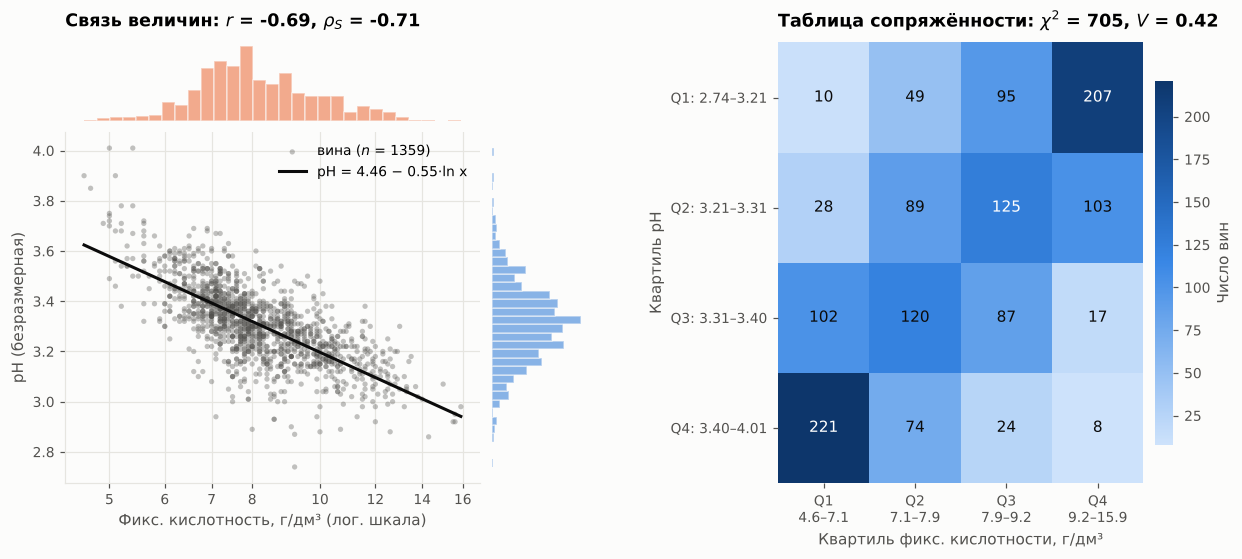

In [7]:
#@title Критерии независимости и графики связи
x, y = wine["fixed acidity"].values, wine["pH"].values
pr = stats.pearsonr(x, y); pr_ln = stats.pearsonr(np.log(x), y)
sp = stats.spearmanr(x, y); kt = stats.kendalltau(x, y)
table = pd.crosstab(pd.qcut(y, 4, labels=["Q1", "Q2", "Q3", "Q4"]), pd.qcut(x, 4, labels=["Q1", "Q2", "Q3", "Q4"]))
chi = stats.chi2_contingency(table)
cramer_v = np.sqrt(chi.statistic / (table.values.sum() * (min(table.shape) - 1)))

tests = pd.DataFrame([
    ("Пирсон r (кислотность в исходной шкале)", pr.statistic, pr.pvalue),
    ("Пирсон r (кислотность в лог. шкале)", pr_ln.statistic, pr_ln.pvalue),
    ("Спирмен ρₛ", sp.statistic, sp.pvalue),
    ("Кендалл τ", kt.statistic, kt.pvalue),
    (f"χ² сопряжённости 4×4, df = {chi.dof}", chi.statistic, chi.pvalue),
    ("Крамер V (сила связи, 0…1)", cramer_v, np.nan),
], columns=["Критерий", "Статистика", "p-value"])
tests["Решение (α = 0.05)"] = np.where(tests["p-value"].isna(), "—",
                                       np.where(tests["p-value"] < ALPHA, "H₀ отвергается", "H₀ не отвергается"))
show(tests, "Таблица К.12 — проверка независимости pH и фиксированной кислотности", fmt="{:.4g}")

b, a = np.polyfit(np.log(x), y, 1)
print(f"Регрессия: pH = {a:.3f} {b:+.3f}·ln(FA)   →   при удвоении кислотности pH меняется на {b * np.log(2):+.3f}, "
      f"на декаду (×10) — на {b * np.log(10):+.2f}")

# ── Рисунок: диаграмма рассеяния с маргинальными гистограммами + таблица сопряжённости
fig = plt.figure(figsize=(13, 5.2))
outer = fig.add_gridspec(1, 2, width_ratios=[5, 3.8], wspace=0.42)
gs = outer[0].subgridspec(2, 2, width_ratios=[4, 0.9], height_ratios=[0.9, 4], wspace=0.05, hspace=0.05)
ax = fig.add_subplot(gs[1, 0]); ax_top = fig.add_subplot(gs[0, 0], sharex=ax); ax_right = fig.add_subplot(gs[1, 1], sharey=ax)
ax.scatter(x, y, s=12, color=STYLE["ink2"], alpha=0.35, edgecolor="none", label="вина ($n$ = %d)" % len(x))
gx = np.geomspace(x.min(), x.max(), 200)
ax.plot(gx, a + b * np.log(gx), color=STYLE["ink"], linewidth=2,
        label=f"pH = {a:.2f} {'−' if b < 0 else '+'} {abs(b):.2f}·ln x")
ax.set_xscale("log")
ticks = [5, 6, 7, 8, 10, 12, 14, 16]
ax.xaxis.set_major_locator(FixedLocator(ticks)); ax.xaxis.set_minor_locator(NullLocator())
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlabel(axis_label("fixed acidity") + " (лог. шкала)"); ax.set_ylabel(axis_label("pH"))
ax.legend(loc="upper right")
lb = np.geomspace(x.min(), x.max(), 30)
ax_top.hist(x, bins=lb, color=STYLE["FA"], alpha=0.55, edgecolor=STYLE["surface"], linewidth=1)
ax_right.hist(y, bins=np.histogram_bin_edges(y, bins="fd"), orientation="horizontal", color=STYLE["pH"], alpha=0.55,
              edgecolor=STYLE["surface"], linewidth=1)
for a_ in (ax_top, ax_right):
    a_.tick_params(labelbottom=False, labelleft=False, bottom=False, left=False)
    a_.grid(False)
    for s_ in a_.spines.values():
        s_.set_visible(False)
ax_top.set_title(f"Связь величин: $r$ = {pr.statistic:.2f}, $\\rho_S$ = {sp.statistic:.2f}")

axh = fig.add_subplot(outer[1])
cmap = mpl.colors.LinearSegmentedColormap.from_list("seq", STYLE["seq"][1:])
im = axh.imshow(table.values, cmap=cmap, aspect="auto")
for (i, j), v in np.ndenumerate(table.values):
    axh.text(j, i, f"{v}", ha="center", va="center", fontsize=10,
             color="white" if v > table.values.max() * 0.55 else STYLE["ink"])
axh.set_xticks(range(4), [f"Q{i + 1}\n{lo:.1f}–{hi:.1f}" for i, (lo, hi) in
                          enumerate(zip(np.quantile(x, [0, .25, .5, .75]), np.quantile(x, [.25, .5, .75, 1])))])
axh.set_yticks(range(4), [f"Q{i + 1}: {lo:.2f}–{hi:.2f}" for i, (lo, hi) in
                          enumerate(zip(np.quantile(y, [0, .25, .5, .75]), np.quantile(y, [.25, .5, .75, 1])))])
axh.grid(False)
axh.set_xlabel("Квартиль фикс. кислотности, г/дм³"); axh.set_ylabel("Квартиль pH")
axh.set_title(f"Таблица сопряжённости: $\\chi^2$ = {chi.statistic:.0f}, $V$ = {cramer_v:.2f}")
for s_ in axh.spines.values():
    s_.set_visible(False)
cb = fig.colorbar(im, ax=axh, fraction=0.046, pad=0.03); cb.set_label("Число вин", color=STYLE["ink2"]); cb.outline.set_visible(False)
plt.show()

**Вывод.** Все четыре критерия отвергают $H_0$ с $p$-value меньше $10^{-140}$: величины зависимы. Связь обратная и сильная ($r = -0.69$, $\rho_S = -0.71$). По таблице сопряжённости из 361 вина нижнего квартиля кислотности 221 попадает в верхний квартиль pH, а из 335 самых кислых вин 207 — в нижний квартиль pH. При независимости в каждой клетке ожидалось бы 80–96 вин.

**Почему связь линейна именно в логарифме.** pH сам является логарифмом, поэтому корреляция с $\ln x$ ($r = -0.71$) сильнее, чем с $x$ ($-0.69$). Наклон регрессии: при росте кислотности в 10 раз pH падает на $\approx 1.27$. Если бы вино было просто раствором слабой кислоты, по формуле $[\mathrm{H^+}] \approx \sqrt{K_a C}$ наклон был бы $-0.5$ на декаду. Но вино — буфер: часть кислот нейтрализована калием [3], и pH подчиняется уравнению Хендерсона–Хассельбаха

$$
\mathrm{pH} = \mathrm{p}K_a + \lg\frac{[\mathrm{A^-}]}{[\mathrm{HA}]} \approx \mathrm{p}K_a + \lg\frac{[\mathrm{K^+}]}{C - [\mathrm{K^+}]}
\quad\Longrightarrow\quad
\frac{d\,\mathrm{pH}}{d \lg C} = -\frac{C}{C - [\mathrm{K^+}]} < -1 .
$$

Наш наклон $-1.27$ укладывается в буферную модель, а не в модель «чистой кислоты». Неизмеренный калий объясняет и то, почему связь не функциональная ($r^2 \approx 0.5$): при той же кислотности pH зависит от того, сколько калия было в винограде.

[↑ к оглавлению](#ktvd-toc)

<a id="ktvd-5"></a>

## К.5 Интерактивный генератор (marimo)

Генератор из второго спринта (`InfoChemRandomGenerator`) вынесен в отдельное реактивное приложение на **marimo**: `ktvd_generator_marimo.py`. В marimo каждая ячейка — функция от своих входов: двигаешь ползунок, и пересчитываются только зависящие от него ячейки. В режиме `marimo run` код скрыт, видна только «панель управления».

**Запуск**

```bash
pip install marimo pandas numpy scipy matplotlib
marimo run ktvd_generator_marimo.py    # режим приложения, код скрыт
marimo edit ktvd_generator_marimo.py   # режим редактирования
```

**Что можно менять**

| Элемент | Назначение |
|---|---|
| Величина | $\lg S$ (ESOL, основная часть), pH или фикс. кислотность (блок КТвД) |
| Метод | полярный метод Марсальи $\to \mathcal{N}(\mu, \sigma^2)$; обратная функция $\to \mathrm{Logistic}(\mu, s)$; эмпирическое квантильное преобразование $\hat{F}_n^{-1}(U)$ |
| $n$, seed | объём синтетической выборки и зерно вихря Мерсенна MT19937 |
| $\mu$, $\sigma$ | брать из данных или задать вручную и посмотреть, как разъезжаются распределения |

**Что показывается:** формула метода в LaTeX, гистограмма и ECDF «данные против генератора», Q-Q график, таблица метрик с относительной ошибкой, двухвыборочный критерий Колмогорова–Смирнова и доля принятых точек для полярного метода (теория $\pi/4 \approx 78.5\,\%$).

Третий метод добавлен из-за находки при проверке спринта 2: оба параметрических генератора симметричны ($\gamma_1 \approx 0$), а у $\lg S$ $\gamma_1 = -0.49$. Квантильное преобразование по эмпирической функции распределения сохраняет асимметрию. Цена — генератор не выходит за пределы наблюдённого диапазона.

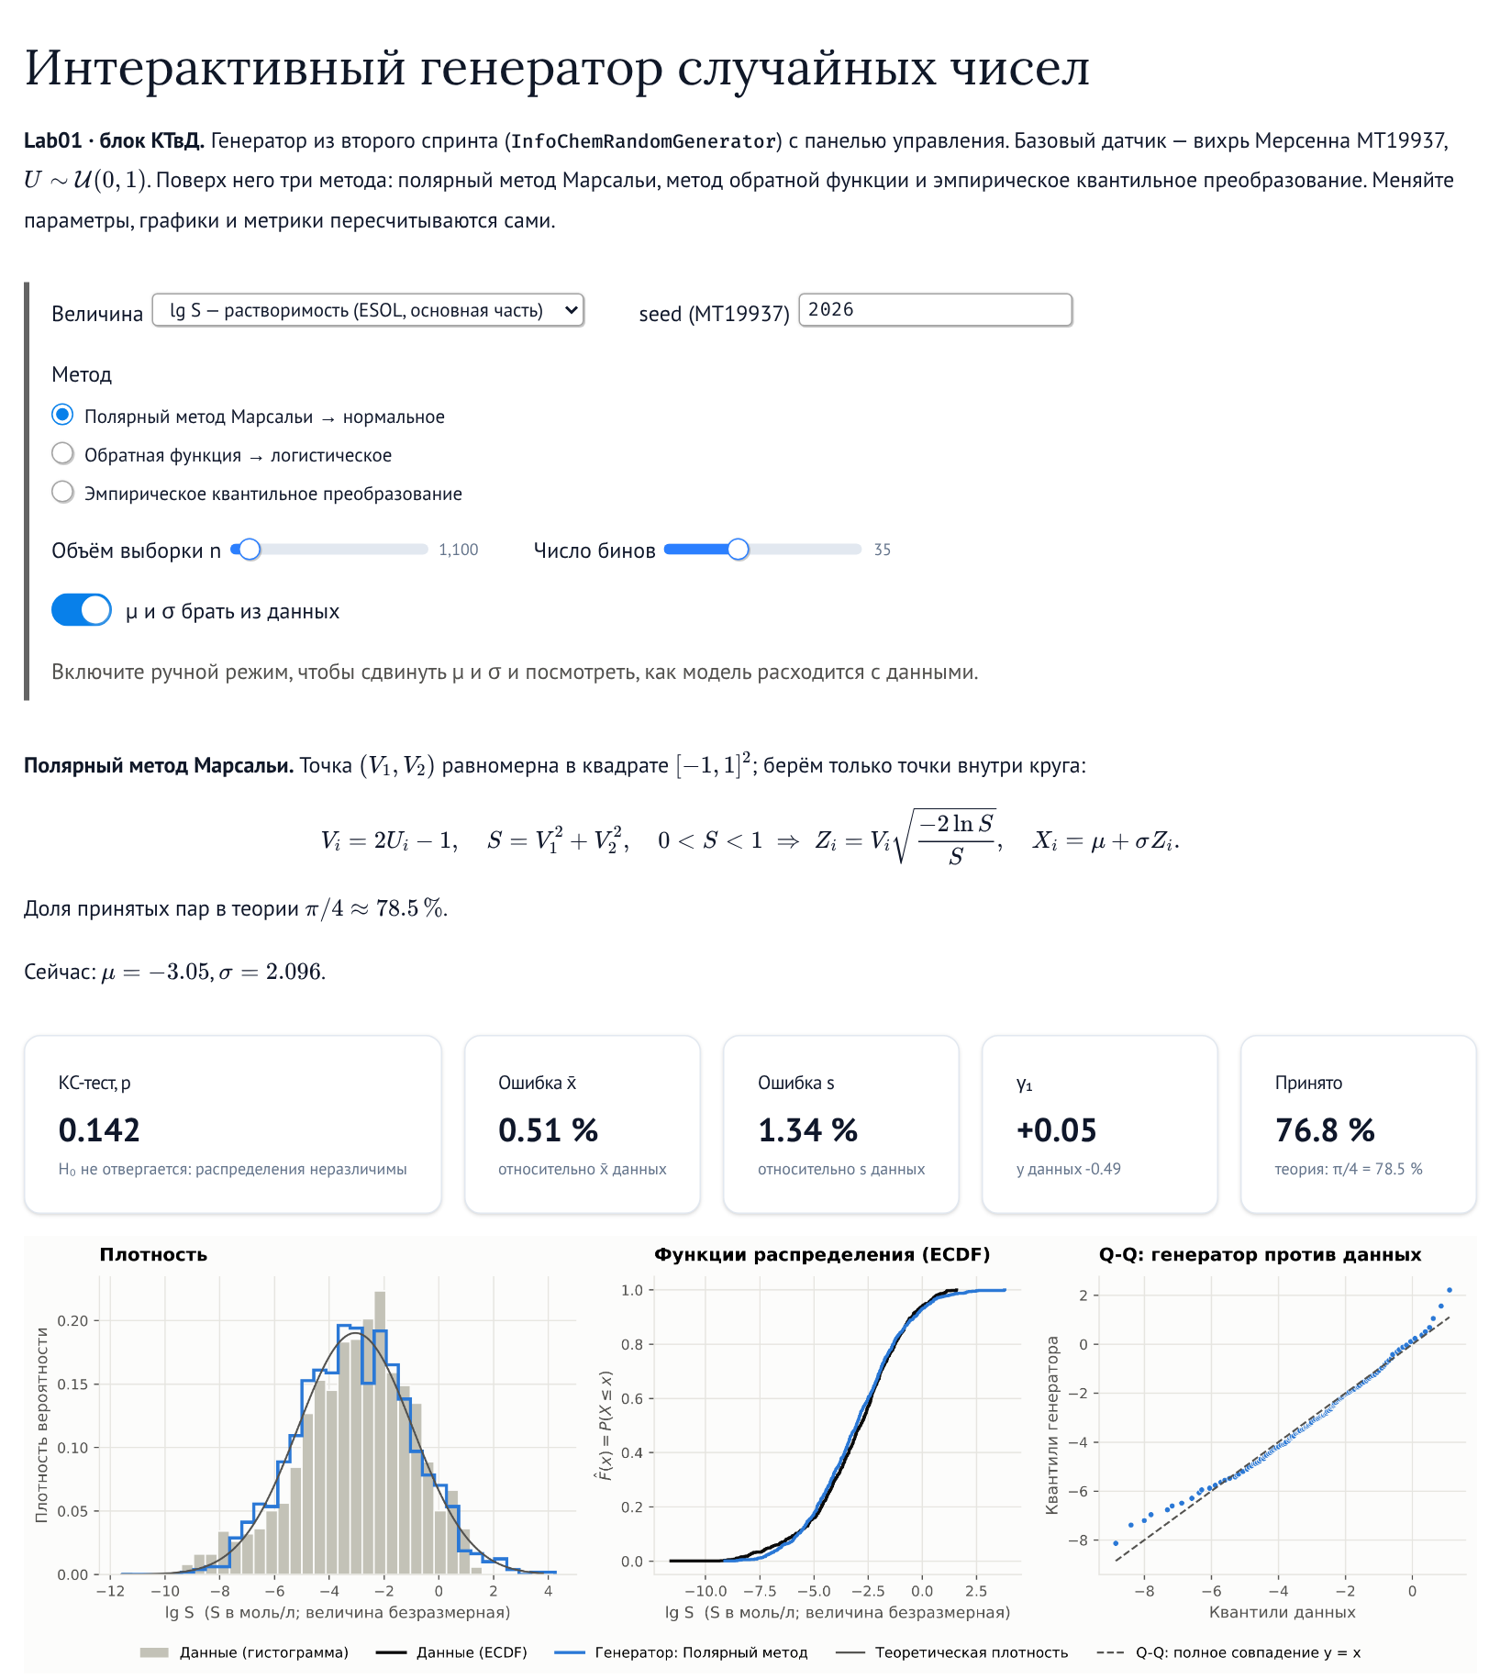

[↑ к оглавлению](#ktvd-toc)

<a id="ktvd-6"></a>

## К.6 Lab resume КТвД

<a id="ktvd-6-1"></a>

### К.6.1 Выводы

1. **Данные.** Wine Quality (red), 1599 строк, из них 240 дубликатов, $n = 1359$ уникальных вин. Порядок строк в файле не случаен (критерий серий, $p < 0.001$), поэтому подвыборки берём только после перемешивания.
2. **Случайность.** Ни pH, ни фиксированная кислотность не вычисляются по остальным показателям: даже лучшая формула оставляет необъяснёнными 30 % и 13 % разброса, ошибка в 6–9 раз больше шага прибора, а у вин-«двойников» значения различаются до $0.35$ ед. pH и $3.1$ г/дм³.
3. **pH** распределён почти симметрично ($\gamma_1 = 0.23$), но с тяжёлыми хвостами ($\gamma_2 = 0.88$). Нормальность отвергается, логистическое распределение $\mathrm{Logistic}(3.308,\ 0.087)$ лучшее по AIC и не отвергается критерием КС.
4. **Фиксированная кислотность** скошена вправо ($\gamma_1 = 0.94$). Логнормальная модель лучшая по AIC, но не идеальная. Для нормализации нужен логарифм или Бокс–Кокс, одна $z$-стандартизация форму не меняет.
5. **Зависимость.** Гипотеза о независимости отвергается всеми критериями, связь обратная и сильная ($\rho_S = -0.71$, $V = 0.42$). Она линейна в логарифмической шкале, и её наклон ($-1.27$ на декаду) согласуется с буферной формулой Хендерсона–Хассельбаха.
6. **Генератор.** Сделан интерактивным в marimo: можно сравнить три метода на трёх величинах и сразу увидеть, где параметрическая модель расходится с данными.

<a id="ktvd-6-2"></a>

### К.6.2 cat_mark_table

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
| `KTVD_STRUCT` | [К.0 Оглавление](#ktvd-toc) |  | Нумерация разделов К.0–К.6, оглавление, якорные ссылки, переходы «↑ к оглавлению» |
| `KTVD_CODE_HIDDEN` | [К.0.1 Чек-лист](#ktvd-0-1) |  | Весь код скрыт (`source_hidden` + Colab-формы) |
| `KTVD_PLOTS` | [К.2.3 EDA](#ktvd-2-3) |  | Единая палитра и стиль, подписи осей с единицами, лог. шкала для кислотности |
| `KTVD_LATEX` | [К.0.2 Обозначения](#ktvd-0-2) |  | Формулы в LaTeX, единые обозначения |
| `KTVD_DATASET` | [К.1 Датасет](#ktvd-1) |  | Отдельный датасет, проверка дубликатов и порядка строк |
| `KTVD_RV_PH` | [К.2 pH](#ktvd-2) |  | Доказательство случайности (регрессия + «двойники»), EDA, подбор распределения |
| `KTVD_RV_FA` | [К.3 Кислотность](#ktvd-3) |  | То же + нормализация (ln, Бокс–Кокс) |
| `KTVD_DEPENDENCE` | [К.4 Зависимость](#ktvd-4) |  | 4 критерия независимости, интерпретация через Хендерсона–Хассельбаха |
| `KTVD_INTERACTIVE` | [К.5 Генератор](#ktvd-5) |  | Интерактивный генератор: 3 метода × 3 величины, метрики и КС-тест на лету |
| `KTVD_MARIMO` | [К.5 Генератор](#ktvd-5) |  | Приложение `ktvd_generator_marimo.py` |

### Литература к блоку

1. Cortez P., Cerdeira A., Almeida F., Matos T., Reis J. Modeling wine preferences by data mining from physicochemical properties // *Decision Support Systems*. — 2009. — Vol. 47, No. 4. — P. 547–553.
2. Leemis L. M., McQueston J. T. Univariate Distribution Relationships // *The American Statistician*. — 2008. — Vol. 62, No. 1. — P. 45–53.
3. Ribéreau-Gayon P., Glories Y., Maujean A., Dubourdieu D. *Handbook of Enology. Vol. 2: The Chemistry of Wine*. — 2nd ed. — Wiley, 2006. — Ch. 1 (органические кислоты, pH и буферные свойства вина).
4. Wald A., Wolfowitz J. On a Test Whether Two Samples are from the Same Population // *Annals of Mathematical Statistics*. — 1940. — Vol. 11, No. 2. — P. 147–162.
5. marimo — reactive Python notebooks. — URL: https://docs.marimo.io

[↑ к оглавлению](#ktvd-toc)